# Мини-проект. Классификация качества вина с использованием SVM

## Постановка задачи

В рамках проекта необходимо решить задачу бинарной классификации качества красного вина с использованием метода опорных векторов (Support Vector Machine, SVM).

Исходный датасет содержит физико-химические характеристики красных вин, такие как кислотность, содержание сахара, уровень алкоголя, концентрация сульфатов и другие показатели. Целевая переменная `quality` представляет собой экспертную оценку качества вина по шкале от 3 до 8 баллов.

## Цель проекта

Цель проекта состоит в проведении исследовательского анализа данных, подготовке признаков и построении модели классификации на основе метода опорных векторов (SVM) с последующим подбором оптимального ядра.

## Задачи исследования

В ходе работы необходимо:

1. Выполнить разведочный анализ данных и изучить распределения признаков.
2. Исследовать взаимосвязи между признаками и целевой переменной.
3. Преобразовать исходную переменную `quality` в бинарный признак качества вина.
4. Выполнить стандартизацию признаков.
5. Обучить модель SVM.
6. Сравнить различные ядерные функции (`linear`, `poly`, `rbf`, `sigmoid`).
7. Подобрать оптимальные гиперпараметры с помощью `GridSearchCV`.
8. Оценить качество итоговой модели по метрике `accuracy` и результатам кросс-валидации.

## Ожидаемый результат

По итогам исследования будет определено ядро SVM, обеспечивающее наилучшее качество классификации для рассматриваемого набора данных, а также проанализированы факторы, оказывающие наибольшее влияние на качество вина.

In [55]:
"""
Импорт библиотек.

"""

# ------------------------------------------------------------------
# 1. Библиотеки для работы с данными
# ------------------------------------------------------------------
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# 2. Библиотеки для визуализации
# ------------------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------
# 3. Работа с файловой системой
# ------------------------------------------------------------------
from pathlib import Path

# ------------------------------------------------------------------
# 4. Предобработка данных
# ------------------------------------------------------------------
from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler
)

# ------------------------------------------------------------------
# 5. Разделение данных и кросс-валидация
# ------------------------------------------------------------------
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score
)

# ------------------------------------------------------------------
# 6. Модель метода опорных векторов
# ------------------------------------------------------------------
from sklearn.svm import SVC

# ------------------------------------------------------------------
# 7. Метрики качества модели
# ------------------------------------------------------------------
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_curve,
    auc
)


In [56]:
"""
Загрузка датасета с характеристиками красных вин
и первичное знакомство с данными.

Цель этапа: проверить доступность файла, загрузить данные
в DataFrame, изучить структуру набора данных и распределение
целевой переменной quality.
"""

# ------------------------------------------------------------------
# 1. Определение пути к директории с данными
# ------------------------------------------------------------------
path = Path.cwd() / 'data'

# ------------------------------------------------------------------
# 2. Проверка альтернативного расположения директории
# ------------------------------------------------------------------
if not path.exists():
    path = Path('data')

# ------------------------------------------------------------------
# 3. Загрузка датасета
# ------------------------------------------------------------------
df = pd.read_csv(
    path / 'winequality-red.csv',
    sep=';'
)

# ------------------------------------------------------------------
# 4. Просмотр первых строк датасета
# ------------------------------------------------------------------
display(df.head())

# ------------------------------------------------------------------
# 5. Анализ структуры данных
# ------------------------------------------------------------------
display(df.info())

# ------------------------------------------------------------------
# 6. Получение описательной статистики
# ------------------------------------------------------------------
display(df.describe())

# ------------------------------------------------------------------
# 7. Анализ распределения целевой переменной
# ------------------------------------------------------------------
display(df['quality'].value_counts())


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


None

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64

### Первичнвй анализ данных
Датасет полностью заполнен, пропущенные значения отсутствуют. Все признаки представлены числовыми переменными, что позволяет напрямую использовать алгоритм SVM после масштабирования.

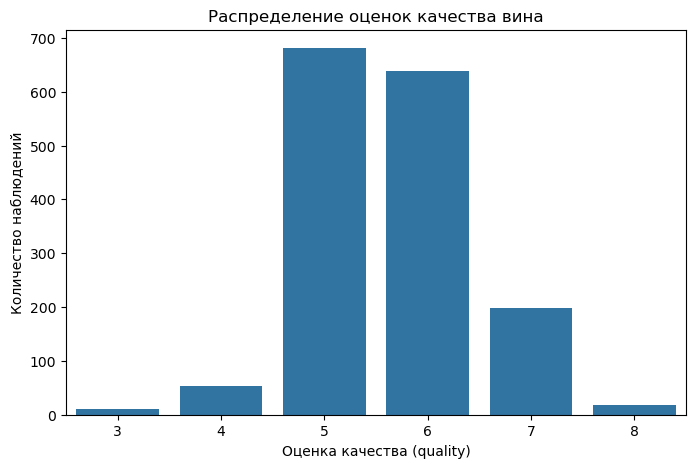

In [57]:
"""
Визуализация распределения целевой переменной quality.

Цель этапа: изучить частоту встречаемости различных оценок
качества вина и определить баланс классов в исходном датасете.
"""

# ------------------------------------------------------------------
# 1. Настройка размера графика
# ------------------------------------------------------------------
plt.figure(figsize=(8, 5))

# ------------------------------------------------------------------
# 2. Построение столбчатой диаграммы распределения quality
# ------------------------------------------------------------------
sns.countplot(
    data=df,
    x='quality'
)

# ------------------------------------------------------------------
# 3. Добавление заголовка и подписей осей
# ------------------------------------------------------------------
plt.title('Распределение оценок качества вина')
plt.xlabel('Оценка качества (quality)')
plt.ylabel('Количество наблюдений')

# ------------------------------------------------------------------
# 4. Отображение графика
# ------------------------------------------------------------------
plt.show()

<Figure size 1400x1000 with 0 Axes>

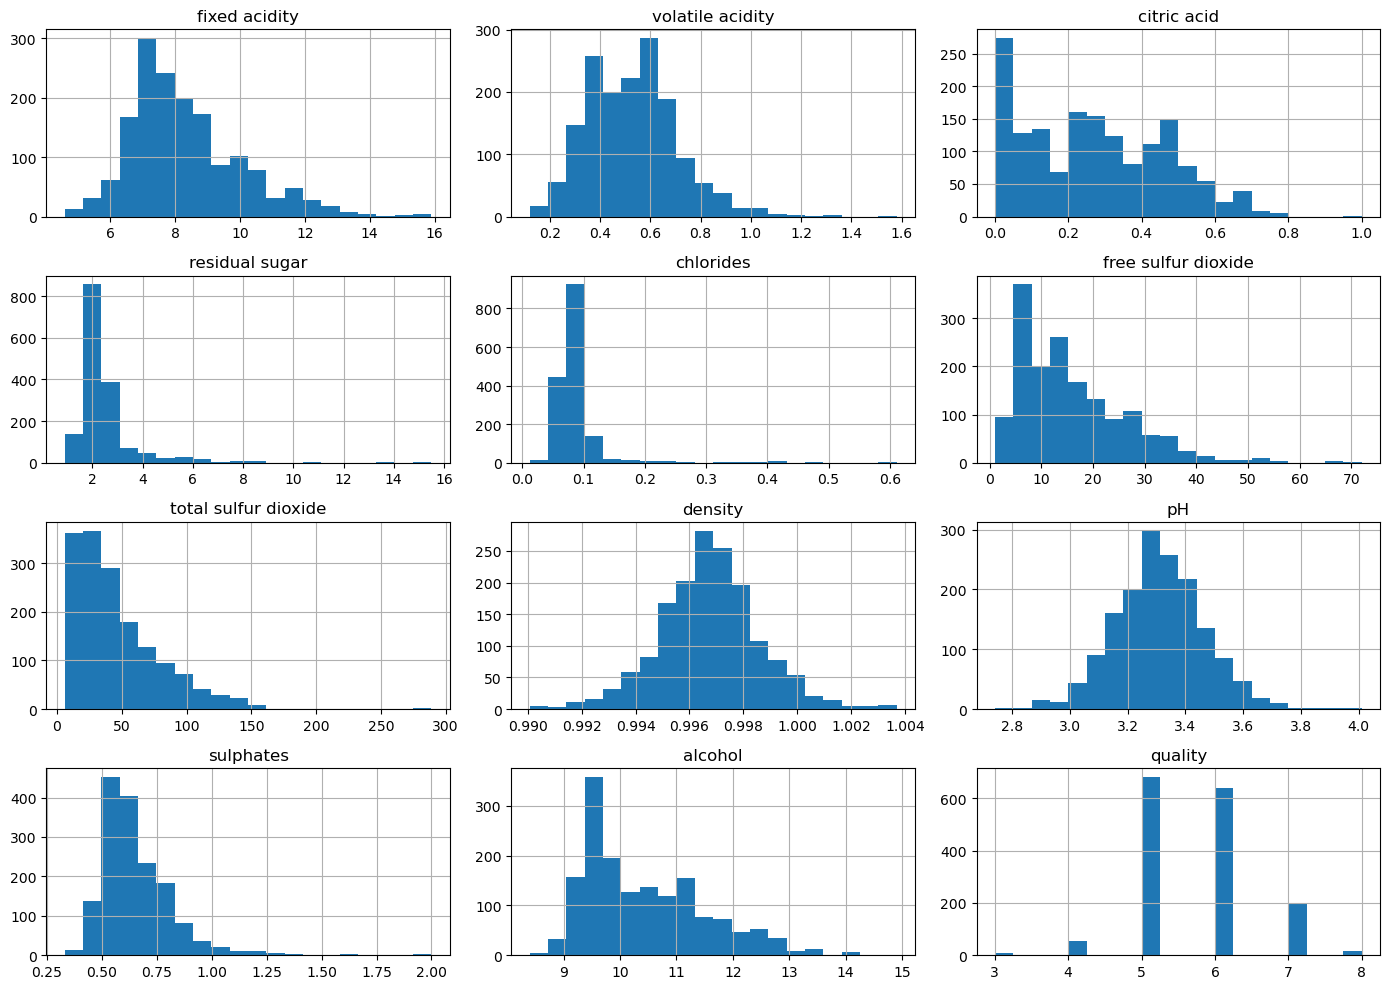

In [58]:
"""
Анализ распределения числовых признаков датасета.

Цель этапа: изучить форму распределений признаков,
выявить возможную асимметрию, выбросы и оценить
необходимость дальнейшего масштабирования данных.
"""

# ------------------------------------------------------------------
# 1. Настройка области отображения графиков
# ------------------------------------------------------------------
plt.figure(figsize=(14, 10))

# ------------------------------------------------------------------
# 2. Построение гистограмм для всех признаков
# ------------------------------------------------------------------
df.hist(
    figsize=(14, 10),
    bins=20
)

# ------------------------------------------------------------------
# 3. Оптимизация расположения графиков
# ------------------------------------------------------------------
plt.tight_layout()

# ------------------------------------------------------------------
# 4. Отображение графиков
# ------------------------------------------------------------------
plt.show()

### Анализ распределений
Анализ распределений показал, что часть признаков имеет правостороннюю асимметрию (chlorides, residual sugar, free sulfur dioxide, total sulfur dioxide), тогда как остальные признаки имеют распределения, близкие к нормальным.

Дополнительное преобразование распределений не выполнялось, так как целью проекта является сравнение различных ядер SVM.

Поскольку алгоритм SVM чувствителен к масштабу признаков, перед его использованием, данные необходимо будет отмасштабировать с помощью StandardScaler. Это будет сделано позже.

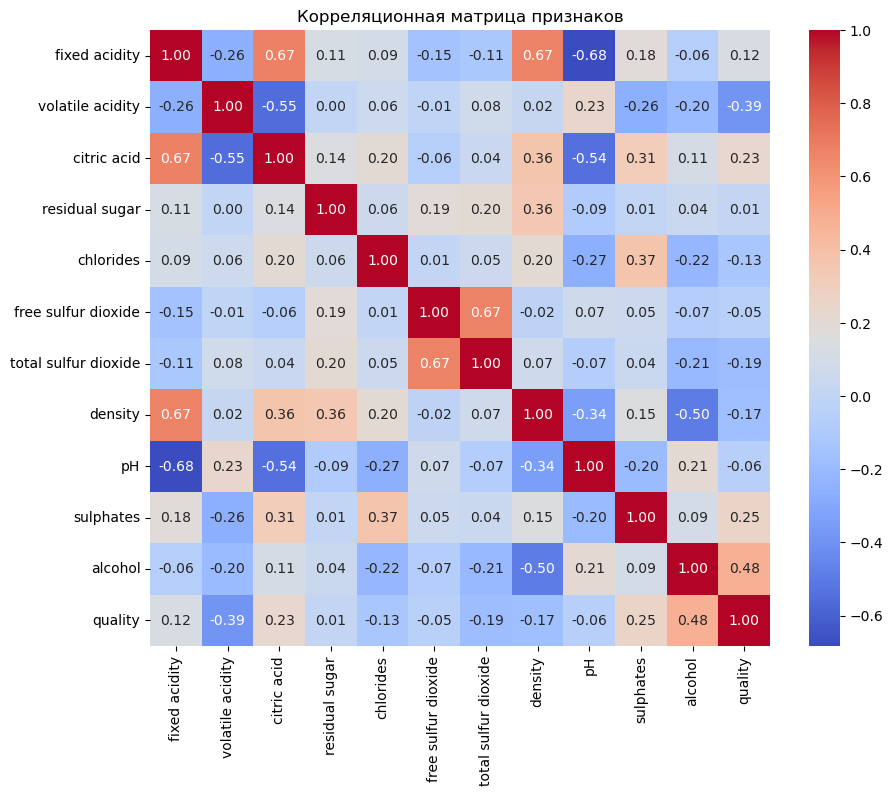

In [59]:
"""
Построение корреляционной матрицы признаков.

Цель этапа: оценить силу и направление линейных взаимосвязей
между признаками датасета, а также определить факторы,
наиболее связанные с качеством вина.
"""

# ------------------------------------------------------------------
# 1. Расчёт матрицы корреляции
# ------------------------------------------------------------------
corr_matrix = df.corr()

# ------------------------------------------------------------------
# 2. Настройка области отображения графика
# ------------------------------------------------------------------
plt.figure(figsize=(10, 8))

# ------------------------------------------------------------------
# 3. Визуализация корреляционной матрицы
# ------------------------------------------------------------------
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

# ------------------------------------------------------------------
# 4. Добавление заголовка
# ------------------------------------------------------------------
plt.title('Корреляционная матрица признаков')

# ------------------------------------------------------------------
# 5. Отображение графика
# ------------------------------------------------------------------
plt.show()

### Анализ корреляционной матрицы

По результатам корреляционного анализа можно сделать следующие выводы:

- Наиболее сильную положительную корреляцию с качеством вина имеет признак **alcohol** (0.48). Это означает, что вина с более высоким содержанием алкоголя, как правило, получают более высокие оценки качества.
- Положительная связь также наблюдается для признаков **sulphates** (0.25) и **citric acid** (0.23), однако она выражена заметно слабее.
- Наиболее сильная отрицательная корреляция с качеством обнаружена у признака **volatile acidity** (-0.39). Увеличение летучей кислотности связано со снижением качества вина.
- Отрицательную, но более слабую связь с качеством показывают признаки **total sulfur dioxide** (-0.19) и **density** (-0.17).

Также можно отметить наличие заметной корреляции между некоторыми признаками:

- **fixed acidity** и **pH** (-0.68);
- **fixed acidity** и **citric acid** (0.67);
- **fixed acidity** и **density** (0.67);
- **free sulfur dioxide** и **total sulfur dioxide** (0.67).

Поскольку целью проекта является построение модели классификации на основе метода опорных векторов (SVM), все признаки будут сохранены для дальнейшего обучения модели. Перед обучением будет выполнена стандартизация признаков с использованием `StandardScaler`.

### Категоризация целевой переменной

Для решения задачи бинарной классификации исходная переменная `quality` должна быть преобразована в категориальную.

Поскольку оценки качества являются целыми числами, условие quality > 6.5 эквивалентно quality ≥ 7.

Для этого вина с оценкой качества ниже 7 отнесем к классу **bad wine**, а вина с оценкой 7 и выше — к классу **good wine**.

Таким образом, задача многоклассовой классификации будет преобразована в задачу бинарной классификации.

In [60]:
"""
Преобразование целевой переменной в бинарный формат.

Цель этапа: перейти от многоклассовой оценки качества вина
к задаче бинарной классификации, разделив вина на группы
с низким и высоким качеством.
"""

# ------------------------------------------------------------------
# 1. Формирование бинарной целевой переменной
# ------------------------------------------------------------------
df['wine_class'] = df['quality'].apply(
    lambda x: 'good wine' if x >= 7 else 'bad wine'
)

# ------------------------------------------------------------------
# 2. Анализ распределения полученных классов
# ------------------------------------------------------------------
df['wine_class'].value_counts()


wine_class
bad wine     1382
good wine     217
Name: count, dtype: int64

### Кодирование целевой переменной

Для обучения модели SVM преобрпзуем категориальную целевую переменную в числовой формат с помощью `LabelEncoder`.

Классу `bad wine` присвоем значение 0, а классу `good wine` — значение 1.

In [61]:
"""
Кодирование целевой переменной.

Цель этапа: преобразовать категориальные классы
в числовой формат, необходимый для обучения модели SVM.

Классу 'bad wine' присваивается значение 0,
а классу 'good wine' — значение 1.
"""

# ------------------------------------------------------------------
# 1. Явное кодирование целевой переменной
# ------------------------------------------------------------------
df['wine_class'] = df['wine_class'].map({
    'bad wine': 0,
    'good wine': 1
})

# ------------------------------------------------------------------
# 2. Проверка результата преобразования
# ------------------------------------------------------------------
df[['quality', 'wine_class']].head()



,quality,wine_class
0,5,0
1,5,0
2,5,0
3,6,0
4,5,0


C:\Users\ekash\AppData\Local\Temp\ipykernel_3376\1952350505.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


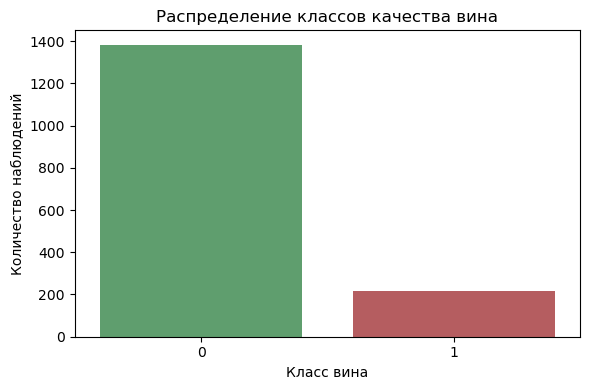

In [62]:
"""
Визуализация распределения бинарных классов.

Цель этапа: оценить баланс классов после преобразования
исходной переменной quality в бинарный формат
('bad wine' и 'good wine').
"""

# ------------------------------------------------------------------
# 1. Настройка области отображения графика
# ------------------------------------------------------------------
plt.figure(figsize=(6, 4))

# ------------------------------------------------------------------
# 2. Построение распределения классов
# ------------------------------------------------------------------
sns.countplot(
    data=df,
    x='wine_class',
    palette=['#55A868', '#C44E52']
)

# ------------------------------------------------------------------
# 3. Оформление графика
# ------------------------------------------------------------------
plt.title('Распределение классов качества вина')
plt.xlabel('Класс вина')
plt.ylabel('Количество наблюдений')

# ------------------------------------------------------------------
# 4. Оптимизация расположения элементов
# ------------------------------------------------------------------
plt.tight_layout()

# ------------------------------------------------------------------
# 5. Отображение графика
# ------------------------------------------------------------------
plt.show()


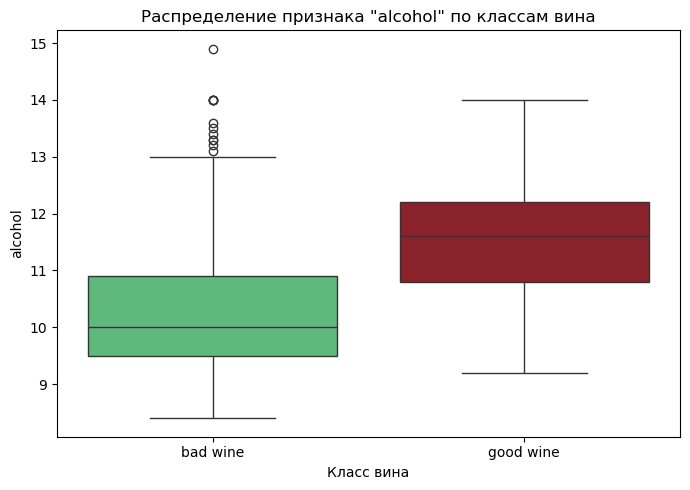

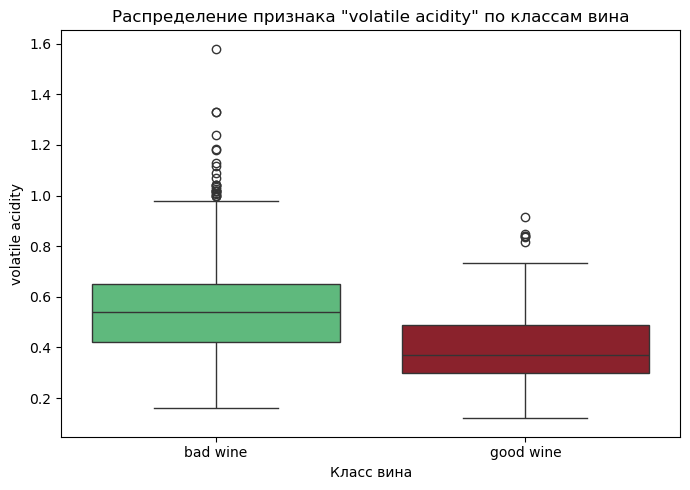

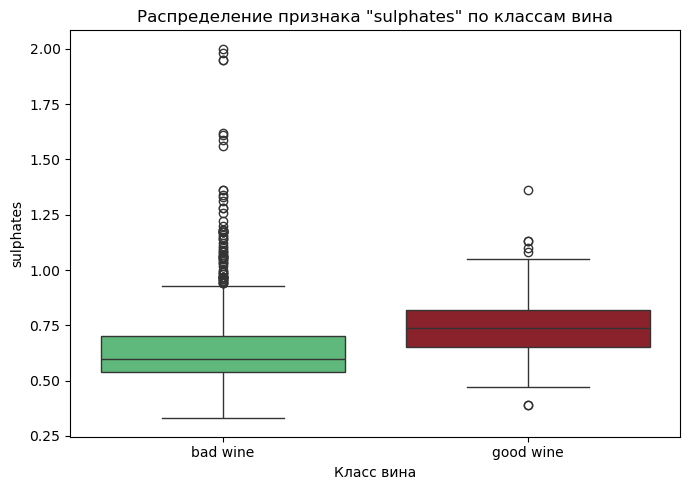

In [63]:
"""
Сравнение распределений наиболее значимых признаков
для различных классов качества вина.

Цель этапа: визуально оценить различия между классами
'bad wine' и 'good wine' по наиболее информативным признакам.
"""

# ------------------------------------------------------------------
# 1. Формирование списка признаков
# ------------------------------------------------------------------
important_features = [
    'alcohol',
    'volatile acidity',
    'sulphates'
]

# ------------------------------------------------------------------
# 2. Определение цветовой схемы классов
# ------------------------------------------------------------------
palette = {
    '0': '#50C878',  # bad wine — изумрудный
    '1': '#9B111E'   # good wine — рубиновый
}

# ------------------------------------------------------------------
# 3. Построение диаграмм размаха
# ------------------------------------------------------------------
for feature in important_features:

    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x=df['wine_class'].astype(str),
        y=feature,
        hue=df['wine_class'].astype(str),
        palette=palette,
        legend=False
    )

    plt.title(
        f'Распределение признака "{feature}" по классам вина'
    )

    plt.xlabel('Класс вина')
    plt.ylabel(feature)

    plt.xticks(
        ticks=[0, 1],
        labels=['bad wine', 'good wine']
    )

    plt.tight_layout()
    plt.show()

In [64]:
"""
Формирование матрицы признаков и целевой переменной.

Цель этапа: разделить набор данных на независимые признаки (X)
и целевую переменную (y), которые будут использоваться
для обучения модели классификации.
"""

# ------------------------------------------------------------------
# 1. Формирование матрицы признаков
# ------------------------------------------------------------------
X = df.drop(['quality', 'wine_class'], axis=1)

# ------------------------------------------------------------------
# 2. Формирование целевой переменной
# ------------------------------------------------------------------
y = df['wine_class']

# ------------------------------------------------------------------
# 3. Проверка размерности данных
# ------------------------------------------------------------------
print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (1599, 11)
y shape: (1599,)


### Разделение выборки

Разделим данные на обучающую и тестовую выборки в соотношении 80:20.

Параметр `stratify=y` использовался для сохранения исходного соотношения классов в обеих выборках.


In [65]:
"""
Разделение данных на обучающую и тестовую выборки.

Цель этапа: выделить независимую тестовую выборку для
оценки качества модели после обучения.

Параметр stratify=y используется для сохранения исходного
соотношения классов в обучающей и тестовой выборках.
"""

# ------------------------------------------------------------------
# 1. Разделение данных на обучающую и тестовую выборки
# ------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Масштабирование признаков

Для подготовки данных к обучению выполним стандартизацию признаков с помощью `StandardScaler`.

Масштабирование особенно важно для метода опорных векторов (SVM), поскольку алгоритм использует расстояния между объектами и чувствителен к различию масштабов признаков.

In [66]:
"""
Масштабирование признаков.

Цель этапа: привести все признаки к единому масштабу
с помощью стандартизации.

Для алгоритма SVM данный шаг является обязательным,
поскольку метод чувствителен к различиям в диапазонах
значений признаков.
"""

# ------------------------------------------------------------------
# 1. Создание объекта стандартизатора
# ------------------------------------------------------------------
scaler = StandardScaler()

# ------------------------------------------------------------------
# 2. Обучение стандартизатора на обучающей выборке
# ------------------------------------------------------------------
X_train_scaled = scaler.fit_transform(X_train)

# ------------------------------------------------------------------
# 3. Преобразование тестовой выборки
# ------------------------------------------------------------------
X_test_scaled = scaler.transform(X_test)

In [67]:
"""
Обучение базовой модели метода опорных векторов (SVM).

Цель этапа: получить базовое значение метрики accuracy
до подбора гиперпараметров и выбора оптимального ядра.
Полученный результат будет использован в качестве
контрольной точки для дальнейшего сравнения моделей.
"""

# ------------------------------------------------------------------
# 1. Создание базовой модели SVM
# ------------------------------------------------------------------
svc = SVC()

# ------------------------------------------------------------------
# 2. Обучение модели на стандартизированных данных
# ------------------------------------------------------------------
svc.fit(
    X_train_scaled,
    y_train
)

# ------------------------------------------------------------------
# 3. Получение прогнозов на тестовой выборке
# ------------------------------------------------------------------
y_pred = svc.predict(
    X_test_scaled
)

# ------------------------------------------------------------------
# 4. Расчёт точности классификации
# ------------------------------------------------------------------
baseline_accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    f'Accuracy базовой модели: {baseline_accuracy:.4f}'
)

Accuracy базовой модели: 0.9000


### Формирование сетки гиперпараметров

Для поиска оптимальной модели будет использован метод полного перебора параметров `GridSearchCV`.

В ходе настройки будут исследованы:

- тип ядра (`kernel`): `linear`, `poly`, `rbf`, `sigmoid`;
- коэффициент регуляризации (`C`);
- параметр влияния отдельных наблюдений (`gamma`).

Основной целью данного этапа является определение ядра, обеспечивающего наилучшее качество классификации вина по метрике `accuracy`.

In [68]:
"""
Подготовка пространства поиска гиперпараметров для модели SVM.

Цель этапа: определить набор значений параметров,
которые будут протестированы в ходе процедуры GridSearchCV
для выбора наиболее эффективной конфигурации модели.
"""

# ------------------------------------------------------------------
# 1. Формирование сетки гиперпараметров
# ------------------------------------------------------------------
param_grid = {
    'kernel': [
        'linear',
        'poly',
        'rbf',
        'sigmoid'
    ],
    'C': [
        0.1,
        1,
        10,
        100
    ],
    'gamma': [
        'scale',
        0.1,
        0.01,
        0.001
    ]
}

### Подбор оптимальных гиперпараметров модели

Для выбора наилучшей конфигурации метода опорных векторов используется процедура `GridSearchCV`.

В ходе подбора выполняется полный перебор всех комбинаций заранее заданных значений параметров:

- типа ядра (`kernel`);
- коэффициента регуляризации (`C`);
- параметра ядра (`gamma`).

Оценка качества моделей производится с помощью 5-блочной кросс-валидации по метрике `accuracy`. Параллельное выполнение вычислений (`n_jobs=-1`) позволяет ускорить процесс обучения.

In [69]:
"""
Подбор оптимальных гиперпараметров модели SVM
с использованием кросс-валидации.

Цель этапа: определить комбинацию параметров,
обеспечивающую наилучшее качество классификации
на обучающей выборке.
"""

# ------------------------------------------------------------------
# 1. Создание объекта GridSearchCV
# ------------------------------------------------------------------
grid = GridSearchCV(
    estimator=SVC(),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# ------------------------------------------------------------------
# 2. Запуск процедуры подбора гиперпараметров
# ------------------------------------------------------------------
grid.fit(
    X_train_scaled,
    y_train
)

,estimator,SVC()
,param_grid,"{'C': [0.1, 1, ...], 'gamma': ['scale', 0.1, ...], 'kernel': ['linear', 'poly', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,1


In [70]:
"""
Анализ результатов подбора гиперпараметров.

Цель этапа: определить оптимальную конфигурацию модели SVM
и оценить качество классификации, полученное в ходе
кросс-валидации.
"""

# ------------------------------------------------------------------
# 1. Вывод оптимальных гиперпараметров
# ------------------------------------------------------------------
print(
    "Лучшие параметры модели:",
    grid.best_params_
)

# ------------------------------------------------------------------
# 2. Вывод лучшего результата кросс-валидации
# ------------------------------------------------------------------
print(
    f"Лучшее значение accuracy (CV): "
    f"{grid.best_score_:.4f}"
)

Лучшие параметры модели: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
Лучшее значение accuracy (CV): 0.8796


In [71]:
"""
Оценка качества лучшей модели, найденной в ходе GridSearchCV.

Цель этапа: проверить, насколько хорошо оптимальная модель
обобщает данные, используя ранее отложенную тестовую выборку.
"""

# ------------------------------------------------------------------
# 1. Получение лучшей модели
# ------------------------------------------------------------------
best_model = grid.best_estimator_

# ------------------------------------------------------------------
# 2. Построение прогнозов на тестовой выборке
# ------------------------------------------------------------------
y_pred = best_model.predict(
    X_test_scaled
)

# ------------------------------------------------------------------
# 3. Расчёт итоговой точности классификации
# ------------------------------------------------------------------
test_accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    f"Accuracy на тестовой выборке: "
    f"{test_accuracy:.4f}"
)

Accuracy на тестовой выборке: 0.9062


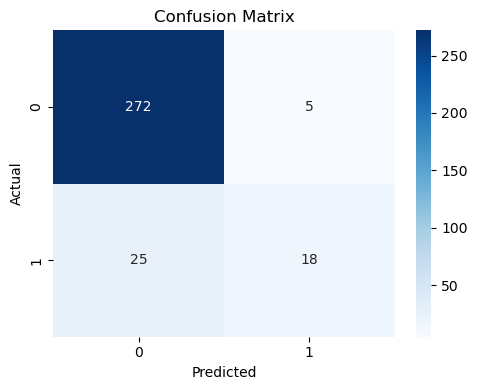

In [72]:
"""
Матрица ошибок (Confusion Matrix).

Цель этапа: оценить качество классификации модели,
проанализировав количество верно и неверно
классифицированных объектов каждого класса.
"""

# ------------------------------------------------------------------
# 1. Построение матрицы ошибок
# ------------------------------------------------------------------
cm = confusion_matrix(y_test, y_pred)

# ------------------------------------------------------------------
# 2. Визуализация матрицы ошибок
# ------------------------------------------------------------------
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

# ------------------------------------------------------------------
# 3. Оформление графика
# ------------------------------------------------------------------
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.tight_layout()
plt.show()

### Анализ матрицы ошибок

Для более детальной оценки качества модели была построена матрица ошибок (Confusion Matrix).

Результаты классификации показали:

- **272** объекта класса `bad wine` были классифицированы верно;
- **18** объектов класса `good wine` были классифицированы верно;
- **5** объектов класса `bad wine` были ошибочно отнесены к классу `good wine`;
- **25** объектов класса `good wine` были ошибочно отнесены к классу `bad wine`.

Полученные результаты свидетельствуют о том, что модель хорошо распознаёт вина класса `bad wine`, однако испытывает определённые трудности при выявлении вин высокого качества (`good wine`).

Такое поведение связано с дисбалансом классов в исходном наборе данных: количество объектов класса `bad wine` значительно превышает количество объектов класса `good wine`. В результате модель чаще отдаёт предпочтение более многочисленному классу.

Несмотря на это, общее качество классификации остаётся высоким, что подтверждается значением метрики Accuracy более 90%. Матрица ошибок показывает, что модель допускает относительно небольшое количество ошибок и в целом успешно решает поставленную задачу бинарной классификации качества вина.

### Примечание
Стоит отметить, что для данной задачи ошибки второго рода (когда хорошее вино классифицируется как плохое) встречаются чаще, чем ошибки первого рода. Это указывает на консервативное поведение модели: алгоритм предпочитает относить объекты к классу `bad wine`, если не уверен в принадлежности вина к категории высокого качества.

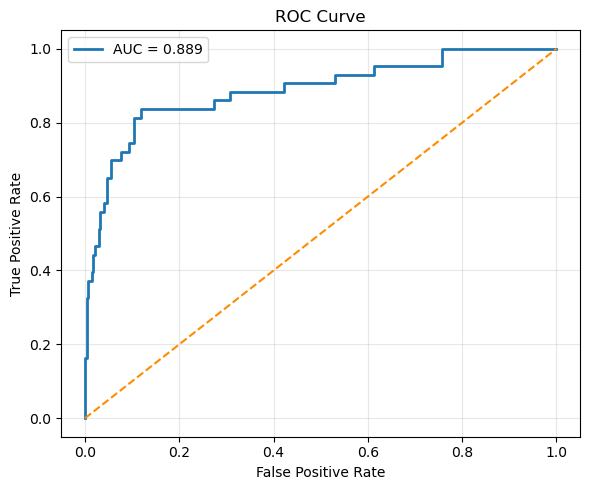

In [73]:
"""
ROC-кривая и метрика AUC.

Цель этапа: оценить способность модели различать классы
на различных порогах классификации.

Метрика AUC показывает качество разделения классов:
чем ближе значение к 1, тем лучше модель отделяет
хорошие вина от плохих.
"""

# ------------------------------------------------------------------
# 1. Получение оценок принадлежности объектов к классам
# ------------------------------------------------------------------
y_prob = best_model.decision_function(X_test_scaled)

# ------------------------------------------------------------------
# 2. Построение данных для ROC-кривой
# ------------------------------------------------------------------
fpr, tpr, _ = roc_curve(y_test, y_prob)

# ------------------------------------------------------------------
# 3. Вычисление площади под ROC-кривой
# ------------------------------------------------------------------
roc_auc = auc(fpr, tpr)

# ------------------------------------------------------------------
# 4. Построение ROC-кривой
# ------------------------------------------------------------------
plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    color='#1f77b4',
    label=f'AUC = {roc_auc:.3f}'
)

# ------------------------------------------------------------------
# 5. Линия случайной классификации
# ------------------------------------------------------------------
plt.plot(
    [0, 1],
    [0, 1],
    '--',
    color='darkorange',
    linewidth=1.5
)

# ------------------------------------------------------------------
# 6. Оформление графика
# ------------------------------------------------------------------
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend()
plt.grid(alpha=0.3)

# ------------------------------------------------------------------
# 7. Отображение графика
# ------------------------------------------------------------------
plt.tight_layout()
plt.show()

### Анализ ROC-кривой

ROC-кривая демонстрирует способность модели разделять классы
на различных порогах классификации.

Полученное значение AUC составило 0.889, что соответствует
хорошему качеству классификации.

Кривая располагается значительно выше линии случайного угадывания,
что свидетельствует о высокой способности модели различать
вина высокого и низкого качества.

Таким образом, выбранная SVM-модель с ядром RBF показывает
не только высокую accuracy, но и уверенное разделение классов
по всей области возможных порогов принятия решения.

In [74]:
"""
Сравнение моделей и итоговая оценка качества.

Цель этапа: проанализировать результаты подбора
гиперпараметров, а также получить надёжную оценку качества
лучшей модели с помощью k-fold кросс-валидации.

В качестве метрики используется accuracy.
"""

# ------------------------------------------------------------------
# 1. Анализ результатов GridSearchCV
# ------------------------------------------------------------------
results = (
    pd.DataFrame(grid.cv_results_)
    .sort_values(
        by='mean_test_score',
        ascending=False
    )
)

display(
    results[
        [
            'param_kernel',
            'param_C',
            'param_gamma',
            'mean_test_score'
        ]
    ].head(10)
)

# ------------------------------------------------------------------
# 2. Выполнение кросс-валидации лучшей модели
# ------------------------------------------------------------------
scores = cross_val_score(
    best_model,
    scaler.fit_transform(X),
    y,
    cv=5,
    scoring='accuracy'
)

# ------------------------------------------------------------------
# 3. Вывод результатов по фолдам
# ------------------------------------------------------------------
print('Cross-validation scores:')
print(scores)

# ------------------------------------------------------------------
# 4. Вычисление средней accuracy
# ------------------------------------------------------------------
print('\nMean accuracy:')
print(scores.mean())

,param_kernel,param_C,param_gamma,mean_test_score
22,rbf,1.0,0.1,0.879596
34,rbf,10.0,scale,0.878811
18,rbf,1.0,scale,0.878033
38,rbf,10.0,0.1,0.876471
50,rbf,100.0,scale,0.874112
58,rbf,100.0,0.01,0.870218
54,rbf,100.0,0.1,0.870208
37,poly,10.0,0.1,0.868649
17,poly,1.0,scale,0.867871
33,poly,10.0,scale,0.866305


Cross-validation scores:
[0.878125   0.846875   0.9        0.84375    0.86520376]

Mean accuracy:
0.8667907523510971


## Вывод

В рамках проекта была решена задача бинарной классификации качества вина с использованием метода опорных векторов (SVM).

На первом этапе был проведён разведочный анализ данных, включающий изучение распределений признаков и анализ корреляционных зависимостей. Было установлено, что наибольшее влияние на качество вина оказывают признаки `alcohol`, `volatile acidity`, `sulphates` и `citric acid`. Также были выявлены умеренные взаимосвязи между отдельными признаками, что свидетельствует о наличии сложной структуры данных.

Для решения задачи классификации исходная переменная `quality` была преобразована в бинарный формат (`bad wine` и `good wine`). После этого признаки были стандартизированы с помощью `StandardScaler`, что является важным этапом подготовки данных для алгоритма SVM.

Подбор гиперпараметров с использованием метода `GridSearchCV` позволил определить оптимальную конфигурацию модели:

- `kernel = 'rbf'`
- `C = 1`
- `gamma = 0.1`

Полученные результаты показали:

- Accuracy на тестовой выборке: **0.906**
- Средняя accuracy по кросс-валидации: **0.867**

Наилучшие результаты продемонстрировало ядро **RBF (Radial Basis Function)**. Это свидетельствует о том, что зависимость между характеристиками вина и его качеством носит нелинейный характер. В отличие от линейного и полиномиального ядер, RBF позволяет строить более гибкие разделяющие поверхности и лучше учитывать сложные взаимосвязи между признаками.

Полученный результат показывает, что для данного набора данных качество вина определяется не отдельным признаком, а совокупностью характеристик, взаимодействующих между собой нелинейным образом. Благодаря способности эффективно моделировать такие зависимости, ядро RBF обеспечило более высокое качество классификации по сравнению с ядрами `linear`, `poly` и `sigmoid`.

Таким образом лучшей моделью для классификации качества вина оказалась модель SVM с радиальной базисной функцией (RBF)